This notebook reproduces Fig. 15.

We find that the time for reaching the adiabatic regime is given by
$$
t_\mathrm{adiab.} \sim 100 \max_\tau \tilde{a}(\tau),
$$
where $\tilde{a}(\tau)$ is the (rescaled) adiabaticity (see `Fig03-resonances.ipynb`), with $\tau=t/t_\mathrm{f}$. The adiabaticity is computed for the Landau-Zener pulses with $z(t=0)=-z(t=t_\mathrm{f})=-10\,x$ (see `Fig02-LZ.ipynb`), and it is maximized over the protocol. Energies are given in units of $x$, and times in units of $\hbar/x$. The red dashed line marks the FAQUAD protocol, at $n_+=3$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun

from HQUAD_lib.hamiltonians import lz_problem
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1


def compute_adiabaticity(alpha: float, beta: float) -> float:
    z_sol = solve_LZ(alpha, beta, x=x)
    s = np.linspace(0, 1, len(z_sol))

    hypermatrix = np.array([lz_problem(x, z) for z in z_sol])
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    # d H / d tau = (d z / d tau) sigma_z
    d_z = np.gradient(z_sol, s)
    partial_hamiltonian = np.array([lz_problem(0, 1) for _ in range(len(z_sol))])
    partial_hamiltonian = partial_hamiltonian * d_z[:, None, None]

    num = np.abs(
        np.einsum(
            "ia,iab,ib->i",
            eigmodes[..., 0].conj(),
            partial_hamiltonian,
            eigmodes[..., 1],
            optimize="greedy",
        )
    )
    den = np.abs(eigvalues[:, 0] - eigvalues[:, 1]) ** 2

    return float(np.max(num / den))

In [3]:
n_plus = np.linspace(
    -5, 20, 101
)  # Increase to enhance resolution (501 values in the manuscript)
beta = 0
alphas = 2 * n_plus - beta

adiabaticity = np.asarray(
    parameterrun(compute_adiabaticity, "alpha", alphas, beta=beta)
)

compute_adiabaticity: [['alpha']]:   0%|          | 0/101 [00:00<?, ?it/s]

# Plot

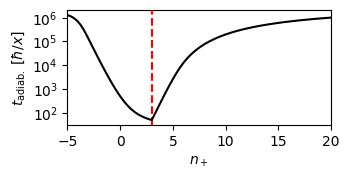

In [4]:
fig, ax = plt.subplots(figsize=(3.4, 1.5))

ax.plot(n_plus, 100 * adiabaticity, zorder=4, c="k")

ax.set_xlim(min(n_plus), max(n_plus))
ax.axvline(3, color="r", ls="--", zorder=3)
ax.set_yscale("log")
ax.set_xlabel(r"$n_+$")
ax.set_ylabel(r"$t_\mathrm{adiab.} \; [\hbar / x]$")
ax.set_yticks(10.0 ** np.arange(2, 6 + 1));